# 02 · Exploratory analysis: Singapore labour market corpus

Scope window **Q3 2021 – Q2 2026**. Inputs: `data/processed/stats.parquet` and `chunks.jsonl`
(built by `python -m policy_agent.ingest.build`). Four analyses, each ending in a finding that changes a design decision.

| # | Analysis | Design consequence |
|---|---|---|
| 1 | Overall vs resident vs citizen unemployment | Residency clarification route; `residency` metadata |
| 2 | Advance-release vs revised retrenchments | Conflict detector; `release_type` metadata |
| 3 | Vacancies vs unemployed; the published ratio | Never recompute the ratio; use the published series |
| 4 | Missingness and corpus profile | Null handling, abstention on suppressed cells, hybrid retrieval |
| 5 | Question-to-passage vocabulary | Lexical retrieval alone is weak for stat cards; hybrid retrieval and metadata filters |

In [1]:
import json
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

from policy_agent.ingest.paths import PROCESSED, SCOPE_FROM, SCOPE_TO
from policy_agent.ingest.revisions import revision_table

plt.rcParams.update(
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25}
)
stats = pd.read_parquet(PROCESSED / "stats.parquet")
chunks = pd.DataFrame(json.loads(line) for line in (PROCESSED / "chunks.jsonl").read_text().splitlines())
W = stats[stats.in_window]


def qdate(p):
    return pd.PeriodIndex(p, freq="Q").to_timestamp(how="end").normalize()


print(f"window {SCOPE_FROM} .. {SCOPE_TO}: {len(W):,} in-window rows of {len(stats):,}; {len(chunks):,} chunks")

window 2021-Q3 .. 2026-Q2: 2,204 in-window rows of 12,418; 2,438 chunks


## 1 · Overall vs resident vs citizen unemployment (seasonally adjusted)

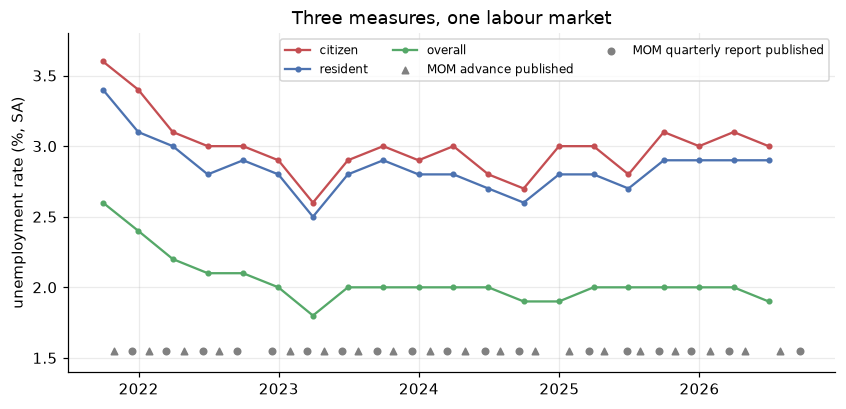

      resident - overall  citizen - resident
min                  0.7                0.10
mean                 0.8                0.15
max                  1.0                0.30
resident SA vs NSA: mean |gap| 0.33 pp, max 0.8 pp (2022-Q2)
2025 resident: annual average (basis not stated) 2.8% vs quarterly SA [2.8, 2.7, 2.9, 2.9]


In [2]:
u = W[(W.indicator == "unemployment_rate") & (W.seasonal_adjustment == "sa") & (W.period_type == "quarter")]
u = u.pivot(index="period", columns="residency", values="value")
pubs = chunks[chunks.doc_type.isin(["advance", "quarterly_report"])].drop_duplicates("source_id")[
    ["pub_date", "doc_type"]
]
pubs = pubs[(pubs.pub_date >= "2021-07-01")]

fig, ax = plt.subplots(figsize=(9, 4))
for col, c in (("citizen", "#c44e52"), ("resident", "#4c72b0"), ("overall", "#55a868")):
    ax.plot(qdate(u.index), u[col], marker="o", ms=3, label=col, color=c)
for kind, mk in (("advance", "^"), ("quarterly_report", "o")):
    d = pd.to_datetime(pubs[pubs.doc_type == kind].pub_date)
    ax.scatter(d, np.full(len(d), 1.55), marker=mk, s=18, color="grey", label=f"MOM {kind.replace('_', ' ')} published")
ax.set_ylim(1.4, 3.8)
ax.set_ylabel("unemployment rate (%, SA)")
ax.legend(ncol=3, fontsize=8, loc="upper right")
ax.set_title("Three measures, one labour market")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()

gap = pd.DataFrame({"resident - overall": u.resident - u.overall, "citizen - resident": u.citizen - u.resident})
print(gap.describe().loc[["min", "mean", "max"]].round(2))
nsa = W[(W.indicator == "unemployment_rate") & (W.residency == "resident") & (W.period_type == "quarter")].pivot(
    index="period", columns="seasonal_adjustment", values="value"
)
d = (nsa.nsa - nsa.sa).abs()
a25 = stats[(stats.source_id == "unemp_rate_resident_a") & (stats.period == "2025")].value.iloc[0]
print(f"resident SA vs NSA: mean |gap| {d.mean():.2f} pp, max {d.max():.1f} pp ({d.idxmax()})")
print(
    f"2025 resident: annual average (basis not stated) {a25}% vs quarterly SA {u.loc['2025-Q1':'2025-Q4', 'resident'].tolist()}"
)

**Finding 1: the headline depends on which measure is quoted.** Across the window the resident rate sits **0.7 to 1.0 pp above** the
overall rate and the citizen rate a further **0.1 to 0.3 pp** above resident (2Q 2026: 1.9% / 2.9% / 3.0%). Within one measure, seasonal
adjustment moves a quarterly resident figure by up to **0.8 pp** (mean 0.33 pp), and the annual average is a different object from any single quarter.
An unqualified "what was unemployment last year?" therefore has several defensible answers a full percentage point apart.

*Design consequence:* ambiguous questions route to `clarify`; `residency` and `seasonal_adjustment` are mandatory metadata; the validator rejects
mixing SA and NSA in one comparison (rule F9). Synthetic memo 07 ("around 2%", no measure) is built on this.

## 2 · Advance release vs revised figures (retrenchments)

advance count stated for 13 of 20 quarters (others give no count, or only a full-year headline)


 period  advance  report  latest_dataset  revision  pct
2021-Q3   2000.0     NaN          1900.0    -100.0 -5.3
2021-Q4   1300.0     NaN          1500.0     200.0 13.3
2023-Q1   4000.0  3820.0          3820.0    -180.0 -4.7
2023-Q2   3200.0  3200.0          3200.0       0.0  0.0
2023-Q3   4100.0  4110.0          4110.0      10.0  0.2
2023-Q4   3200.0  3460.0          3460.0     260.0  7.5
2024-Q1   3000.0     NaN          3030.0      30.0  1.0
2024-Q2   3100.0  3270.0          3270.0     170.0  5.2
2024-Q3   2900.0     NaN          3050.0     150.0  4.9
2025-Q1   3300.0  3590.0          3590.0     290.0  8.1
2025-Q2   3500.0     NaN          3540.0      40.0  1.1
2025-Q3   3500.0     NaN          3670.0     170.0  4.6
2026-Q2   4500.0     NaN          4620.0     120.0  2.6


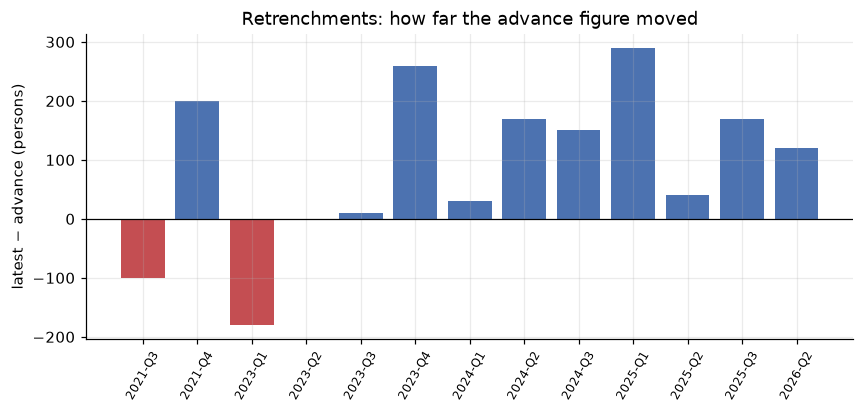

up 10, down 2, unchanged 1; mean +89, mean |rev| 132, max |rev| 290 (2025-Q1); median 2.6% of the final figure


In [3]:
rev = revision_table().dropna(subset=["advance", "latest_dataset"]).copy()
rev["revision"] = rev.latest_dataset - rev.advance
rev["pct"] = rev.revision / rev.latest_dataset * 100
total_q = len(revision_table())
print(f"advance count stated for {len(rev)} of {total_q} quarters (others give no count, or only a full-year headline)")
print(rev[["period", "advance", "report", "latest_dataset", "revision", "pct"]].round(1).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(rev))
ax.bar(x, rev.revision, color=np.where(rev.revision >= 0, "#4c72b0", "#c44e52"))
ax.set_xticks(x, rev.period, rotation=60, fontsize=8)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("latest − advance (persons)")
ax.set_title("Retrenchments: how far the advance figure moved")
plt.show()
print(
    f"up {int((rev.revision > 0).sum())}, down {int((rev.revision < 0).sum())}, unchanged {int((rev.revision == 0).sum())}; "
    f"mean {rev.revision.mean():+.0f}, mean |rev| {rev.revision.abs().mean():.0f}, max |rev| {rev.revision.abs().max():.0f} "
    f"({rev.loc[rev.revision.abs().idxmax(), 'period']}); median {rev.pct.median():.1f}% of the final figure"
)

**Finding 2: advance figures are routinely revised, mostly upward.** For the 13 quarters where the Advance Release states a count, the
final figure is higher in **10**, lower in 2, unchanged in 1; the typical revision is ~130 persons (≈2.6% of the final count) and the largest is
**+290 (1Q 2025: 3,300 → 3,590)**. Other revisions in the corpus follow the same pattern: 2Q 2024 3,100 → 3,270, and 3Q 2025 total employment growth
+24,800 → +25,100 and citizen unemployment 3.0% → 3.1%.

*Design consequence:* every report chunk carries `release_type` and `release_date`; when sources disagree the conflict detector must surface **both**
values with dates and prefer the latest, never silently pick one (failure modes F5 and F10). Synthetic memos 01 and 02 quote the superseded values.
Caveat: 13 quarters, regex extraction validated by hand on every match; a small sample, so this is directional.

## 3 · Labour demand vs supply

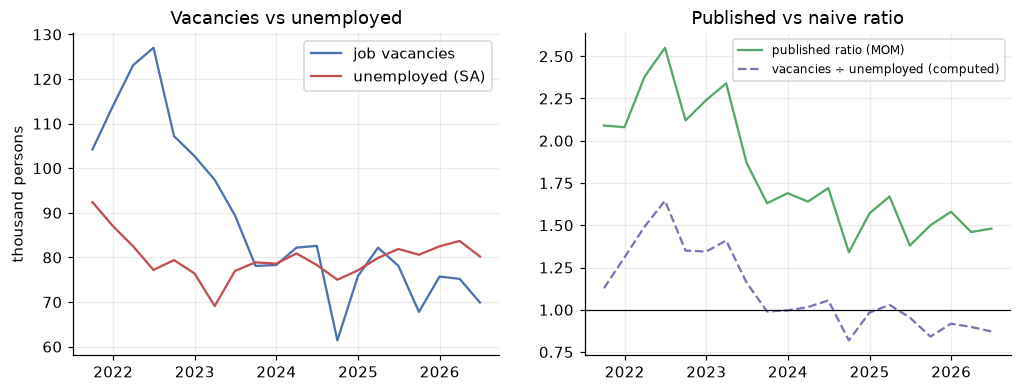

published ratio: peak 2022-Q2 2.55, low 2024-Q3 1.34; > 1 in 20/20 quarters
naive ratio:     peak 2022-Q2 1.65, low 2024-Q3 0.82; > 1 in 11/20 quarters
mean |published − naive| = 0.71; correlation 0.971
denominator implied by the published ratio = 54% to 69% of the unemployed-persons series


In [4]:
jv = W[W.source_id == "job_vacancy_q"].set_index("period").value
ue = W[(W.source_id == "unemployed_overall_q") & (W.seasonal_adjustment == "sa")].set_index("period").value
pub = W[W.source_id == "vacancy_unemployed_ratio_q"].set_index("period").value
naive = jv / ue

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8))
a.plot(qdate(jv.index), jv / 1e3, label="job vacancies", color="#4c72b0")
a.plot(qdate(ue.index), ue / 1e3, label="unemployed (SA)", color="#c44e52")
a.set_ylabel("thousand persons")
a.legend()
a.set_title("Vacancies vs unemployed")
b.plot(qdate(pub.index), pub, label="published ratio (MOM)", color="#55a868")
b.plot(qdate(naive.index), naive, "--", label="vacancies ÷ unemployed (computed)", color="#8172b3")
b.axhline(1, color="k", lw=0.8)
b.set_title("Published vs naive ratio")
b.legend(fontsize=8)
plt.show()

implied = jv / pub
print(
    f"published ratio: peak {pub.idxmax()} {pub.max():.2f}, low {pub.idxmin()} {pub.min():.2f}; > 1 in {int((pub > 1).sum())}/{len(pub)} quarters"
)
print(
    f"naive ratio:     peak {naive.idxmax()} {naive.max():.2f}, low {naive.idxmin()} {naive.min():.2f}; > 1 in {int((naive > 1).sum())}/{len(naive)} quarters"
)
print(f"mean |published − naive| = {(pub - naive).abs().mean():.2f}; correlation {np.corrcoef(pub, naive)[0, 1]:.3f}")
print(
    f"denominator implied by the published ratio = {(implied / ue).min():.0%} to {(implied / ue).max():.0%} of the unemployed-persons series"
)

**Finding 3: dividing the vacancy series by the unemployed series does not reproduce the published vacancy-to-unemployed ratio.** Vacancies fell from a
127,000 peak (2Q 2022) to 69,900 (2Q 2026) and the published ratio from 2.55 to 1.48, so vacancies still outnumber jobseekers in every quarter.
But dividing job vacancies by the unemployed-persons series gives **0.87 in 2Q 2026**, i.e. *fewer* vacancies than unemployed (it is above 1 in only
11 of 20 quarters, versus 20 of 20 for the published ratio), and differs from the official ratio by **0.71 on average**. The two move together (r = 0.97), so the trend agrees but the level and the headline conclusion do not.
The denominator implied by the published ratio is only **54–69%** of unemployed persons; the dataset does not define it, and MOM's text refers to
"jobseekers", which may be a different population from the labour-force-survey unemployed (the data does not say).

*Design consequence:* `compute_change` may compute changes **of** a published series, but the agent should **quote the published ratio rather than substituting its own division**: it
reports the published `vacancy_to_unemployed_ratio`, notes that its denominator is undocumented in `limitations`, and the `calculation` eval cases avoid
this derivation. This is a concrete F9 (measure mismatch) risk.

## 4 · Data quality and corpus profile

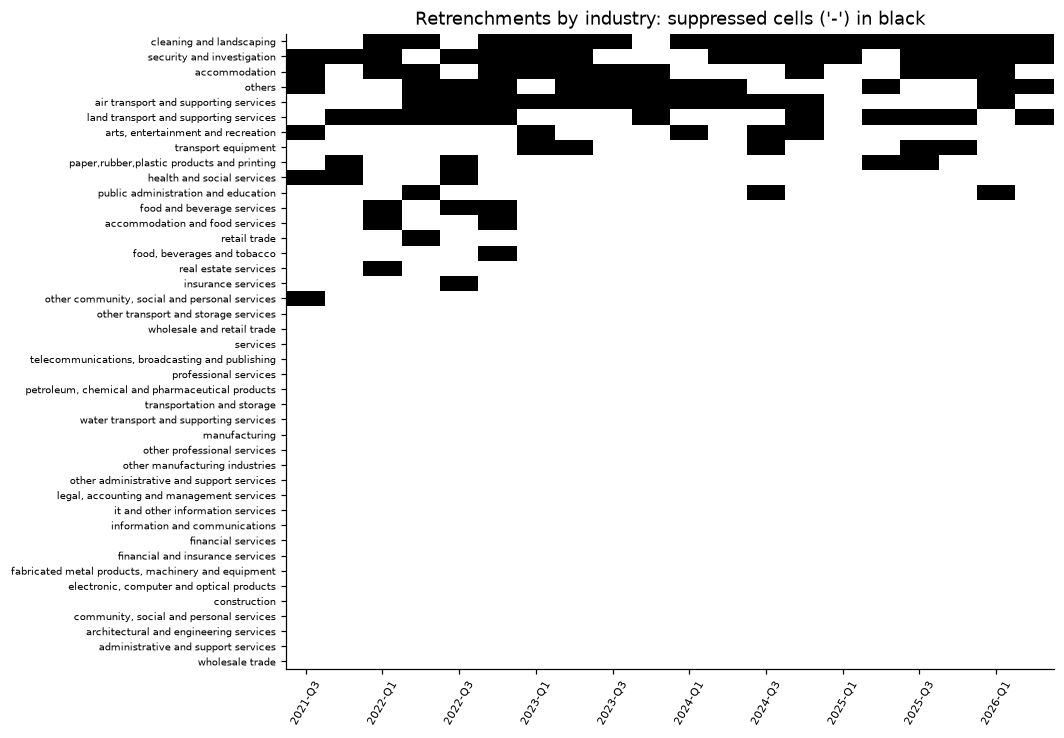

null cells in file: 628 total, 108 in window; 12.9% of in-window retrenchment-by-industry cells; vacancy-by-industry in window: 0 nulls
industry labels in window: 42 (a single quarter has ~36 non-null)


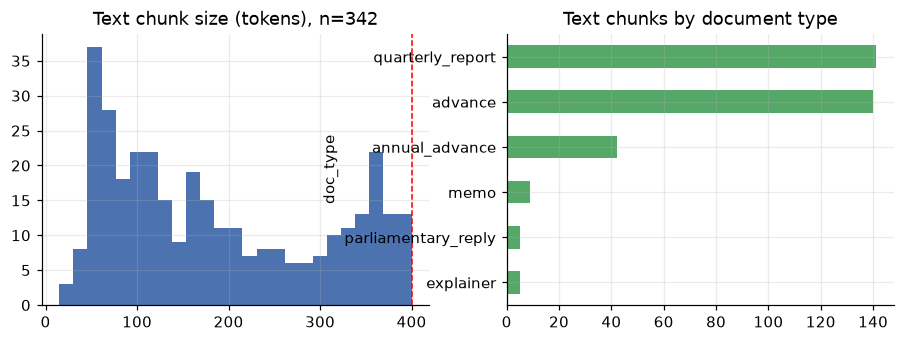

2,096 stat cards vs 342 prose chunks (cards are 86% of the index)
example card : Singapore number of job vacancies, the year 2024: 75,500 (Source: MOM via data.gov.sg, dataset d_89c02a8fe06893fa97b47a6bdf3626be, retrieved 2026-10-2
example prose: 1. Singapore’s labour market performed better in 3Q 2021 compared to the previous quarter. Resident employment grew at a faster pace, although total e


In [5]:
ind = W[W.source_id == "retrenched_by_industry_q"].pivot(index="industry", columns="period", values="value")
order = ind.isna().sum(axis=1).sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(9, 7.5))
ax.imshow(ind.loc[order].isna().to_numpy(), aspect="auto", cmap="Greys", interpolation="nearest")
ax.set_yticks(range(len(order)), order, fontsize=6.5)
ax.set_xticks(range(0, ind.shape[1], 2), ind.columns[::2], rotation=60, fontsize=7)
ax.grid(False)
ax.set_title("Retrenchments by industry: suppressed cells ('-') in black")
plt.show()

nulls = stats[stats.value.isna()]
print(
    f"null cells in file: {len(nulls)} total, {int(nulls.in_window.sum())} in window; "
    f"{ind.isna().mean().mean():.1%} of in-window retrenchment-by-industry cells; vacancy-by-industry in window: "
    f"{int(W[(W.source_id == 'job_vacancy_by_industry_q') & W.value.isna()].shape[0])} nulls"
)
print(f"industry labels in window: {ind.shape[0]} (a single quarter has ~{int(ind.notna().sum().median())} non-null)")

t = chunks[chunks.doc_type != "stat_card"]
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.2))
a.hist(t.tokens, bins=25, color="#4c72b0")
a.axvline(400, color="r", ls="--", lw=1)
a.set_title(f"Text chunk size (tokens), n={len(t)}")
t.groupby("doc_type").size().sort_values().plot.barh(ax=b, color="#55a868")
b.set_title("Text chunks by document type")
plt.show()
cards = chunks[chunks.doc_type == "stat_card"]
print(f"{len(cards):,} stat cards vs {len(t)} prose chunks (cards are {len(cards) / len(chunks):.0%} of the index)")
print("example card :", cards.text.iloc[0][:150])
print("example prose:", t[t.doc_type == "quarterly_report"].text.iloc[0][:150])

**Finding 4: suppression is concentrated and the index is card-dominated.** 12.9% of in-window retrenchment-by-industry cells are suppressed
(`-`), concentrated in small industries such as *cleaning and landscaping* (16 of 20 quarters), *security and investigation* (15) and *accommodation* (12);
vacancy-by-industry has none in the window. Suppressed cells produce **no** stat card, so a question about them must abstain rather than impute. Industry
labels also mix classification vintages and parents with children (42 labels in the window); only three roll-ups were verified (aggregate = sum of
components within rounding), so cross-industry sums are unsafe.

Stat cards are **86% of the index** (2,096 of 2,438 chunks) and use phrasing ("2Q 2026", "seasonally adjusted") unlike the report prose
("3Q 2025", "Total employment grew by 25,100"). A BM25-only retriever will be flooded by near-identical cards for numeric queries while dense retrieval
blurs adjacent quarters, which is the motivation for hybrid retrieval with metadata filters (H1) and for keeping cards in a separate, filterable `doc_type`.

Vocabulary overlap between the evaluation questions and their gold passages is analysed in Finding 5.

## 5 · Do questions share words with their gold passages?

            count  median  mean
card                           
prose          28     0.6  0.61
stat cards     33     0.5  0.57
gold chunks with <40% of the question's content words: 10 of 61, in cases ['K02', 'K04', 'M01', 'M04', 'M06', 'M07']


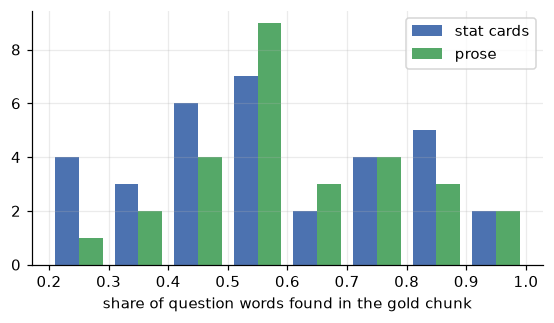

overall card : Singapore overall unemployment rate (seasonally adjusted), 2Q 2025: 2%
resident card: Singapore resident unemployment rate (seasonally adjusted), 2Q 2025: 2
citizen card : Singapore citizen unemployment rate (seasonally adjusted), 2Q 2025: 2.
word Jaccard overall~resident 0.70, resident~citizen 0.70


In [6]:
import re
from policy_agent.eval import checks
from policy_agent.eval.models import EvalCase

STOP = set(
    "the a an of in to and or for was were is are what how by did does do from with that this as at on it its be between according mom's moms their than more".split()
)


def toks(t):
    return {w for w in re.findall(r"[a-z0-9]+", t.lower()) if w not in STOP}


by_id = {c.chunk_id: c for c in chunks.itertuples()}
rows = []
for case in checks.load("eval_cases.jsonl", EvalCase):
    q = toks(case.question)
    for cid in case.gold_chunk_ids:
        ch = by_id[cid]
        rows.append({"case": case.id, "card": ch.doc_type == "stat_card", "overlap": len(q & toks(ch.text)) / len(q)})
ov = pd.DataFrame(rows)
print(
    ov.groupby("card")
    .overlap.agg(["count", "median", "mean"])
    .rename(index={True: "stat cards", False: "prose"})
    .round(2)
)
low = ov[ov.overlap < 0.4]
print(
    f"gold chunks with <40% of the question's content words: {len(low)} of {len(ov)}, in cases {sorted(low.case.unique())}"
)

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(
    [ov[ov.card].overlap, ov[~ov.card].overlap], bins=8, label=["stat cards", "prose"], color=["#4c72b0", "#55a868"]
)
ax.set_xlabel("share of question words found in the gold chunk")
ax.legend()
plt.show()

cards = chunks[chunks.doc_type == "stat_card"]


def card_text(src, period, who):
    pat = re.escape(f"Singapore {who} unemployment rate (seasonally adjusted), {period}")
    return cards[(cards.source_id == src) & cards.text.str.contains(pat)].text.iloc[0]


a, b, c = (card_text(f"unemp_rate_{w}_q", "2Q 2025", w) for w in ("overall", "resident", "citizen"))


def j(x, y):
    X, Y = set(x.lower().split()), set(y.lower().split())
    return len(X & Y) / len(X | Y)


print("overall card :", a[:70])
print("resident card:", b[:70])
print("citizen card :", c[:70])
print(f"word Jaccard overall~resident {j(a, b):.2f}, resident~citizen {j(b, c):.2f}")

**Finding 5: questions overlap only partly with their gold evidence, and sibling stat cards are nearly indistinguishable.** Of the 57 gold
chunks, 33 are stat cards and 24 are report prose. A question shares a median of **50% of its content words with its gold stat card** versus
**63% with gold prose**, and 9 gold chunks (in cases K04, M01, M04, M06, M07) share under 40%, usually because the question paraphrases ("retrenched",
"annual figures", "data sources") where the card uses a template. Worse, the stat cards for the three residency measures in the same quarter
differ by **one word** (overall / resident / citizen) and their value, with a word Jaccard of **0.70** between each pair even though the cards include
a long source suffix, so keyword matching cannot tell them apart without the residency term and dense retrieval will blur them.

*Design consequence:* this is the empirical case for hybrid retrieval (H1) and, more specifically, for **metadata filters** on `doc_type`, `period` and
`residency` extracted by the router (R5), plus structured lookup through `query_statistic` for numeric questions rather than relying on card retrieval.
Caveat: 36 hand-written questions by one author, so the overlap figures describe this set rather than real user phrasing.

## Summary of design consequences

1. **Residency and adjustment are first-class metadata**; ambiguous questions clarify instead of guessing (Finding 1).
2. **Release type and date are first-class**; conflicts show both values (Finding 2).
3. **Published series should be quoted rather than re-derived**, in particular the vacancy ratio (Finding 3).
4. **Suppressed cells mean abstain**; filter by `doc_type` so stat cards do not drown prose (Finding 4).
5. **Keyword overlap is not enough**; combine hybrid retrieval with metadata filters and structured lookup (Finding 5).